In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats  
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = yf.download('AAPL', start='2020-01-01', end='2026-01-01')
ts = df['Close']
print(ts.head())

[*********************100%***********************]  1 of 1 completed

Ticker           AAPL
Date                 
2020-01-02  72.400520
2020-01-03  71.696655
2020-01-06  72.267929
2020-01-07  71.928047
2020-01-08  73.085083


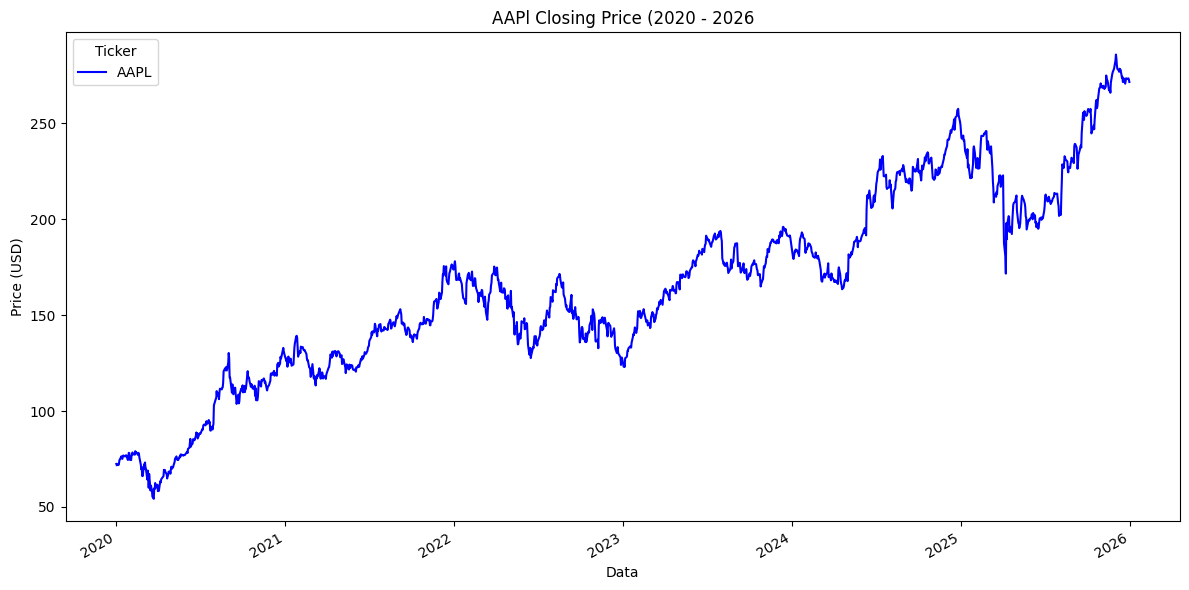

In [3]:
ts.plot(figsize=(12, 6), title='AAPl Closing Price (2020 - 2026', color='blue')
plt.xlabel('Data')
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.show()

In [4]:
skew = ts.skew().values[0]
kurt = ts.kurtosis().values[0]
jb_stat, jb_p = stats.jarque_bera(ts)

print(f'Skewness        : {skew:.4f}  (ideal: -0.5 to 0.5)')
print(f'Kurtosis        : {kurt:.4f}  (ideal: -1 to 1)')
print(f'Jarque-Bera p   : {jb_p:.4f}')
print('Normal ' if jb_p > 0.05 else 'Not Normal try log transform ')

Skewness        : 0.0934  (ideal: -0.5 to 0.5)
Kurtosis        : -0.3993  (ideal: -1 to 1)
Jarque-Bera p   : 0.0021
Not Normal try log transform 


In [5]:
# Log Transformation
ts_log = np.log(ts)

skew2 = ts_log.skew().values[0]
kurt2 = ts_log.kurtosis().values[0]
jb_stats2 , jb_p2 = stats.jarque_bera(ts_log)

print('---- After Transformation---')
print(f'Skewness : {skew2:.4f}')
print(f'Kurtosis: {kurt2:.4f}')
print(f'Jarque - Bera p : {jb_p2:.4f}')
print('Normal' if jb_p2 > 0.05 else ' Not Normal')

# Hetroskedasticity on originl
rolling_std = ts.rolling(window=30).std()
std_cv = (rolling_std.std() / rolling_std.mean()).values[0]

print(f'\n===== Heteroskedasticity =====')
print(f'Rolling Std CV  : {std_cv:.4f}')
print('Constant Variance ' if std_cv < 0.3 else 'Heteroskedastic   log transform needed')

---- After Transformation---
Skewness : -0.7607
Kurtosis: 0.4555
Jarque - Bera p : 0.0000
 Not Normal

===== Heteroskedasticity =====
Rolling Std CV  : 0.4140
Heteroskedastic   log transform needed


If rolling std stays flat → constant variance 

If rolling std goes up/down → heteroskedastic 

We are using the old data because the log transformation made skewness worse

In [6]:
def adf_test(series, label='Series'):
    result = adfuller(series)
    print(f'---{label}---')
    print(f'ADF Statistic : {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    print(f'Stationary'  if result[1] < 0.05 else 'Not Stationary')
    print()
adf_test(ts, 'Original Price')

---Original Price---
ADF Statistic : -0.9192
p-value: 0.7816
Not Stationary



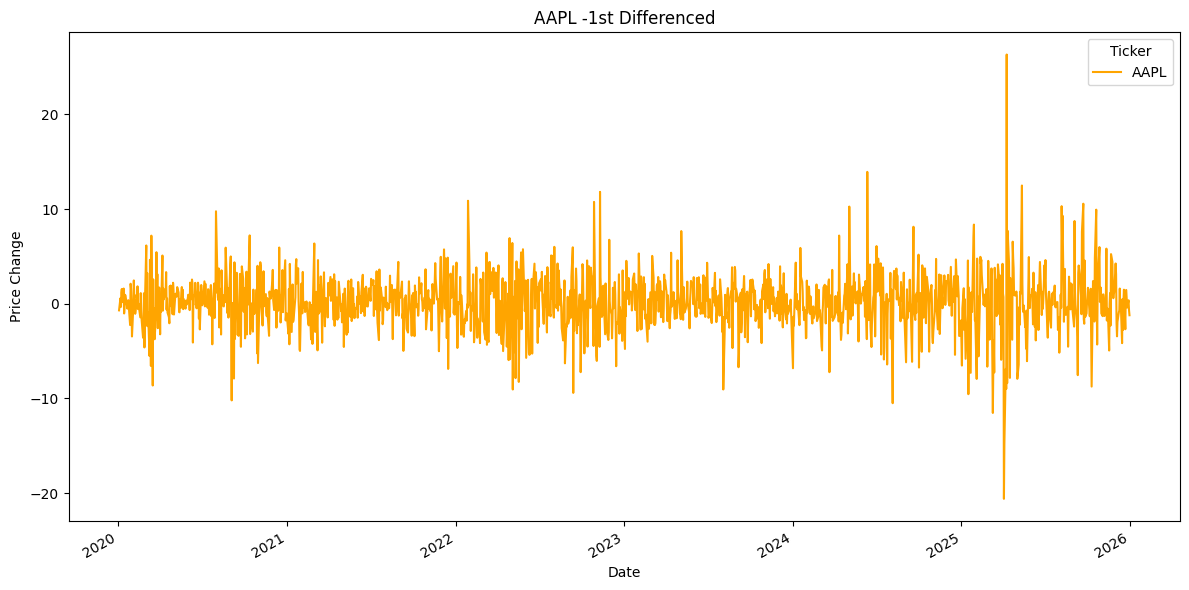

---1st Differnced---
ADF Statistic : -38.0789
p-value: 0.0000
Stationary



In [7]:
ts_diff = ts.diff().dropna()
ts_diff.plot(figsize=(12,6), title='AAPL -1st Differenced', color='orange')
plt.xlabel('Date')
plt.ylabel('Price Change')
plt.tight_layout()
plt.show()
adf_test(ts_diff, '1st Differnced')

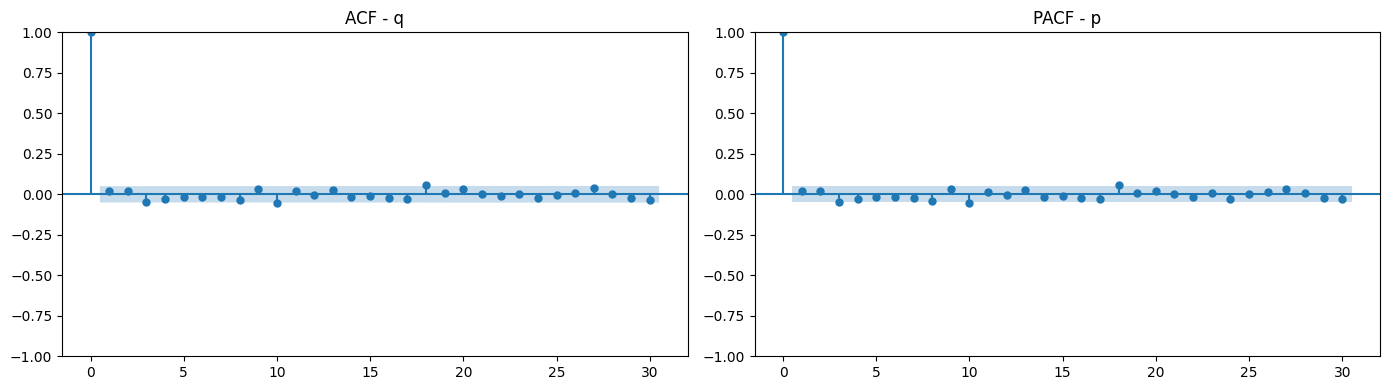

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(ts_diff, ax=ax[0], lags=30, title='ACF - q')
plot_pacf(ts_diff, ax=ax[1], lags=30, title='PACF - p')
plt.tight_layout()
plt.show()

In [9]:
model = ARIMA(ts, order=(0,1,0))
result = model.fit()
print(result.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1508
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -3789.527
Date:                Tue, 10 Mar 2026   AIC                           7581.053
Time:                        11:00:44   BIC                           7586.371
Sample:                             0   HQIC                          7583.034
                               - 1508                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         8.9473      0.154     58.203      0.000       8.646       9.249
Ljung-Box (L1) (Q):                   0.50   Jarque-Bera (JB):              3076.22
Prob(Q):                              0.48   Pr

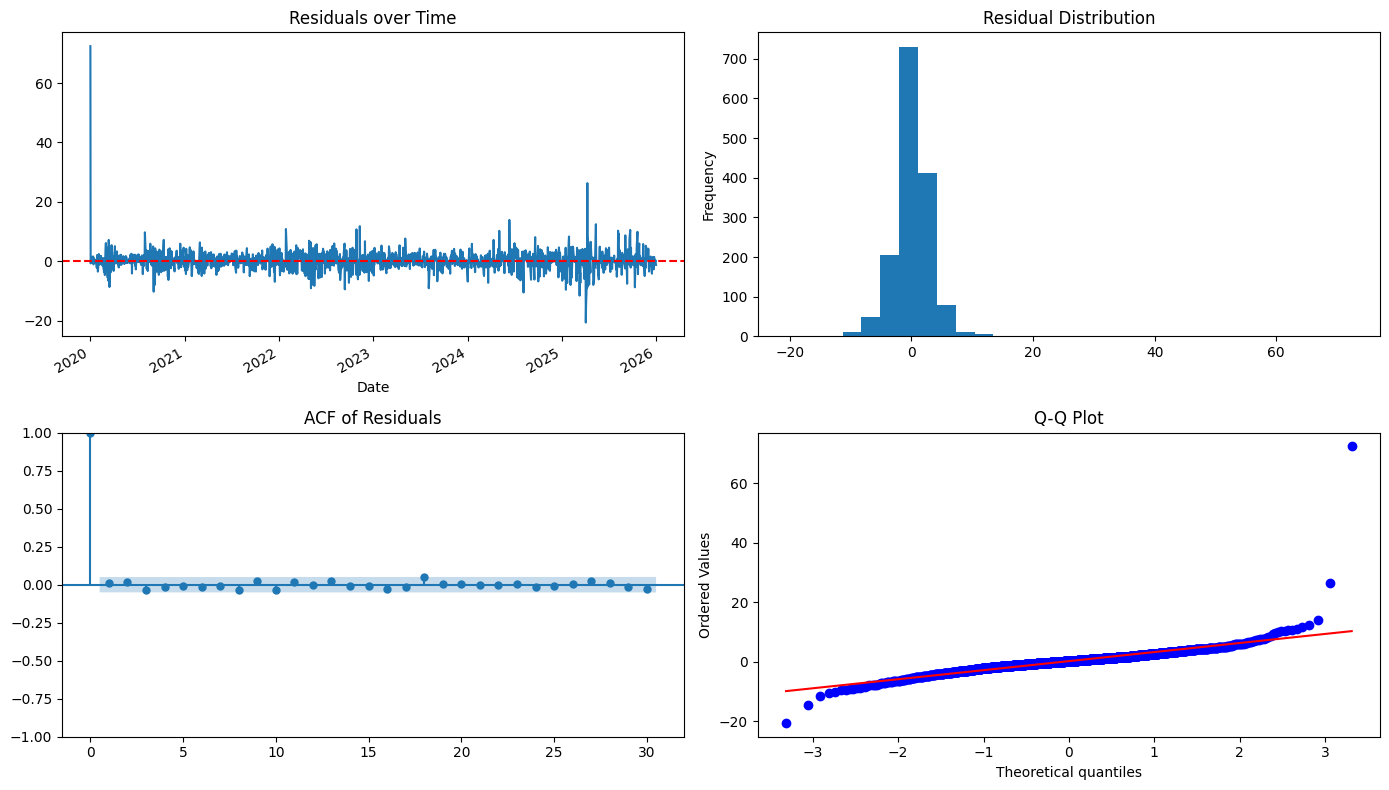

In [10]:
residuals = result.resid

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. Residual plot
residuals.plot(ax=axes[0,0], title='Residuals over Time')
axes[0,0].axhline(y=0, color='red', linestyle='--')

# 2. Residual distribution
residuals.plot(kind='hist', ax=axes[0,1], bins=30, title='Residual Distribution')

# 3. ACF of residuals
plot_acf(residuals, ax=axes[1,0], lags=30, title='ACF of Residuals')

# 4. Q-Q plot
stats.probplot(residuals, plot=axes[1,1])
axes[1,1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

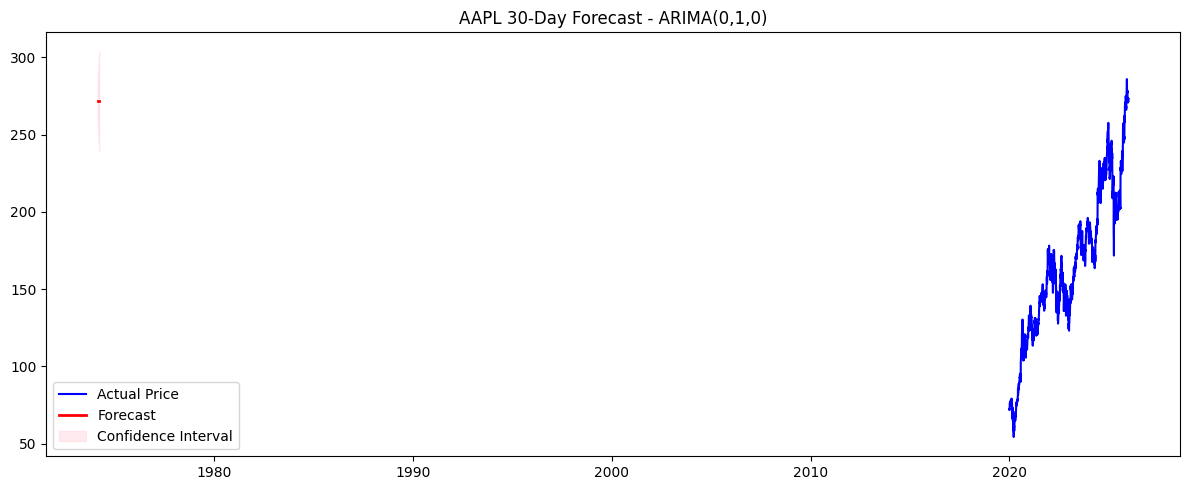

In [11]:
forecast = result.forecast(steps=30)
conf_int = result.get_forecast(steps=30).conf_int()

plt.figure(figsize=(12, 5))
plt.plot(ts, label='Actual Price', color='blue')
plt.plot(forecast, label='Forecast', color='red', linewidth=2)
plt.fill_between(conf_int.index,
                 conf_int.iloc[:, 0],
                 conf_int.iloc[:, 1],
                 color='pink', alpha=0.3, label='Confidence Interval')
plt.title('AAPL 30-Day Forecast - ARIMA(0,1,0)')
plt.legend()
plt.tight_layout()
plt.show()